In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10,5)
np.random.seed(42)

In [3]:
n = 2000

2. Import the dataset

In [4]:
df = pd.read_csv("sales_data.csv")

3.Explore the data

In [5]:
print(df.info())
print("\nMissing Values:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 2010 entries, 0 to 2009
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Order_ID      2010 non-null   int64  
 1   Date          2010 non-null   str    
 2   Category      2010 non-null   str    
 3   Region        2010 non-null   str    
 4   Quantity      2010 non-null   int64  
 5   Unit_Price    2010 non-null   float64
 6   Customer_Age  1959 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 110.1 KB
None

Missing Values:
 Order_ID         0
Date             0
Category         0
Region           0
Quantity         0
Unit_Price       0
Customer_Age    51
dtype: int64

Duplicate Rows: 10


,Order_ID,Quantity,Unit_Price,Customer_Age
count,2010.000000,2010.00000,2010.000000,1959.000000
mean,2000.907960,4.98408,254.860328,43.441552
std,576.803471,2.56071,142.880297,14.918352
min,1001.000000,1.00000,5.310000,18.000000
25%,1502.250000,3.00000,135.285000,31.000000
50%,2001.500000,5.00000,258.175000,43.000000
75%,2499.750000,7.00000,375.310000,57.000000
max,3000.000000,9.00000,499.930000,69.000000


4.Data Cleaning 

remove duplicates

In [6]:
df = df.drop_duplicates().reset_index(drop=True)

Fill missing ages with the medan 

In [7]:
df["Customer_Age"] = df["Customer_Age"].fillna(df["Customer_Age"].median())

Convert date column properly 

In [9]:
df["Date"] = pd.to_datetime(df["Date"])
print("Missing Values after cleaning:",df.isnull().sum().sum())
print("Rows after cleaning:",len(df))

Missing Values after cleaning: 0
Rows after cleaning: 2000


# 5. Feature Engineering

In [10]:
df.head()

,Order_ID,Date,Category,Region,Quantity,Unit_Price,Customer_Age
0,1001,2024-07-24 14:20:49.824912,Electronics,South,9,494.30,23.0
1,1002,2024-09-23 09:37:00.510255,Clothing,North,4,175.43,61.0
2,1003,2024-06-06 00:41:03.631815,Furniture,East,9,35.57,40.0
3,1004,2024-08-24 06:33:18.999499,Groceries,South,4,368.50,50.0
4,1005,2024-07-25 07:52:33.376688,Electronics,South,2,263.26,33.0


In [13]:
df["Revenue"] = df["Quantity"] + df["Unit_Price"]
df["Month"] = df["Date"].dt.month
df["Month_Name"]= df["Date"].dt.strftime("%b")
df["Weekday"] = df["Date"].dt.day_name()
df.head()

,Order_ID,Date,Category,Region,Quantity,Unit_Price,Customer_Age,Revenue,Month,Month_Name,Weekday
0,1001,2024-07-24 14:20:49.824912,Electronics,South,9,494.30,23.0,503.30,7,Jul,Wednesday
1,1002,2024-09-23 09:37:00.510255,Clothing,North,4,175.43,61.0,179.43,9,Sep,Monday
2,1003,2024-06-06 00:41:03.631815,Furniture,East,9,35.57,40.0,44.57,6,Jun,Thursday
3,1004,2024-08-24 06:33:18.999499,Groceries,South,4,368.50,50.0,372.50,8,Aug,Saturday
4,1005,2024-07-25 07:52:33.376688,Electronics,South,2,263.26,33.0,265.26,7,Jul,Thursday


# Age groups using NumPy/Pandas binning

In [14]:
df["Age_Group"] = pd.cut(
    df["Customer_Age"],
    bins=[17, 25, 35, 50, 70],
    labels=["18-25", "26-35", "36-50", "51-70"]
)

df.head()

,Order_ID,Date,Category,Region,Quantity,Unit_Price,Customer_Age,Revenue,Month,Month_Name,Weekday,Age_Group
0,1001,2024-07-24 14:20:49.824912,Electronics,South,9,494.30,23.0,503.30,7,Jul,Wednesday,18-25
1,1002,2024-09-23 09:37:00.510255,Clothing,North,4,175.43,61.0,179.43,9,Sep,Monday,51-70
2,1003,2024-06-06 00:41:03.631815,Furniture,East,9,35.57,40.0,44.57,6,Jun,Thursday,36-50
3,1004,2024-08-24 06:33:18.999499,Groceries,South,4,368.50,50.0,372.50,8,Aug,Saturday,36-50
4,1005,2024-07-25 07:52:33.376688,Electronics,South,2,263.26,33.0,265.26,7,Jul,Thursday,26-35


# CELL 6: Key Business Metrics

In [16]:
total_revenue = df["Revenue"].sum()
avg_order = df["Revenue"].mean()
best_category = df.groupby("Category")["Revenue"].sum().idxmax()
best_region = df.groupby("Region")["Revenue"].sum().idxmax()

print(f"Total Revenue : ${total_revenue:,.2f}")
print(f"Average Order Size: ${avg_order:,.2f}")
print(f"Top Category : {best_category}")
print(f"Top Region : {best_region}")

Total Revenue : $519,817.18
Average Order Size: $259.91
Top Category : Groceries
Top Region : East


# CELL 7: Monthly Revenue Trend (Line Chart)

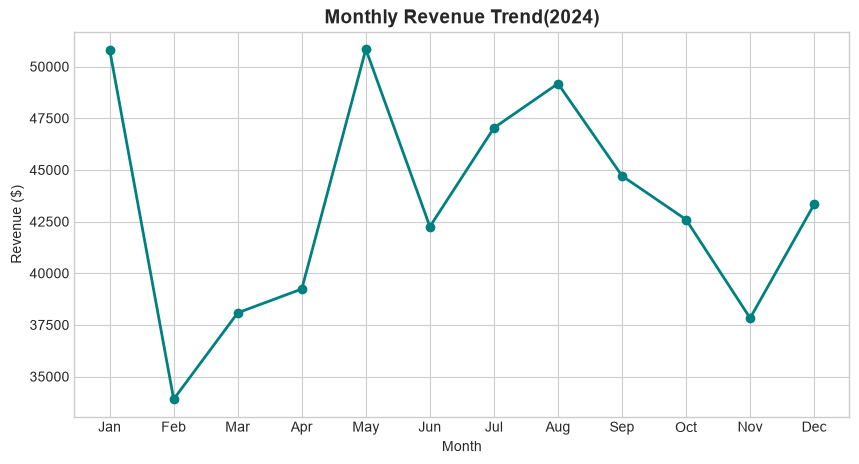

In [17]:
month_order = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
monthly = df.groupby("Month_Name")["Revenue"].sum().reindex(month_order)
plt.plot(monthly.index,monthly.values,marker="o",color="teal",linewidth=2 )
plt.title("Monthly Revenue Trend(2024)",fontsize=14,fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.show()

# CELL 8: Revenue by Category (Bar Chart)

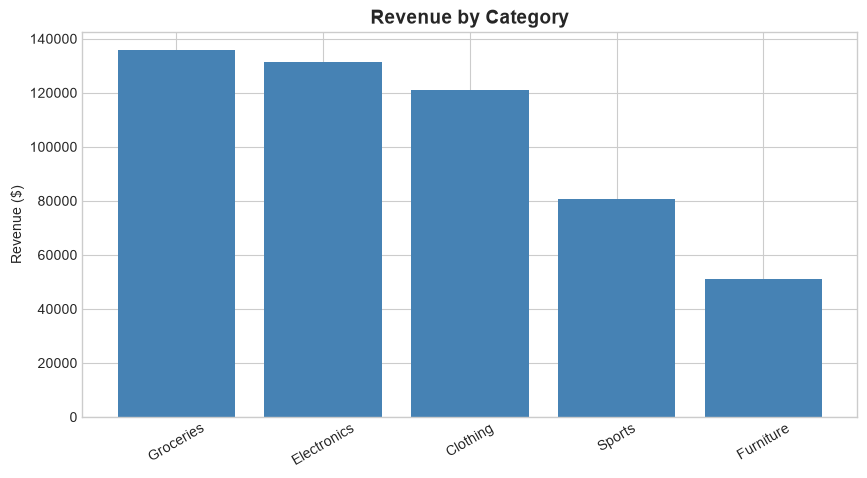

In [21]:
cat_rev = df.groupby("Category")["Revenue"].sum().sort_values(ascending=False)

plt.bar(cat_rev.index, cat_rev.values, color="steelblue")
plt.title("Revenue by Category", fontsize=14, fontweight="bold")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=30)
plt.show()

# CELL 9: Regional Share (Pie Chart)

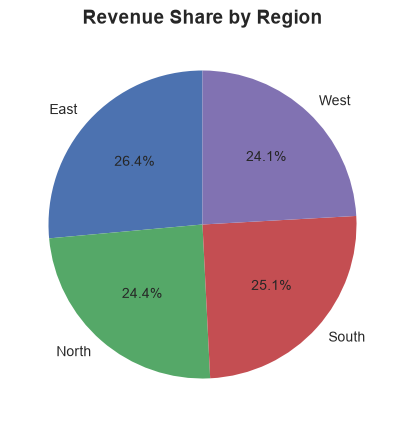

In [22]:
region_rev = df.groupby("Region")["Revenue"].sum()

plt.pie(region_rev, labels=region_rev.index, autopct="%1.1f%%",
        startangle=90, colors=["#4C72B0", "#55A868", "#C44E52", "#8172B2"])
plt.title("Revenue Share by Region", fontsize=14, fontweight="bold")
plt.show()

# CELL 10: Customer Age Distribution (Histogram)

In [ ]:
plt.hist(df["Customer_Age"], bins=15, color="coral", edgecolor="black")
plt.axvline(df["Customer_Age"].mean(),color="")